## IMPORTS AND SET UP

In [1]:
import sys
sys.path.append('../')
from src import decision_tree as dt
import pandas as pd 
from src import classification_error_analysis as cea
from src import xgboost as xgb


# Load the features (X)
x_train = pd.read_parquet('../data/split/x_train.parquet', engine='fastparquet')
x_val = pd.read_parquet('../data/split/x_val.parquet', engine='fastparquet')
x_test = pd.read_parquet('../data/split/x_test.parquet', engine='fastparquet')

# Load the targets (y) and squeeze back into a Series (since you used .to_frame() to save)
y_train = pd.read_parquet('../data/split/y_train.parquet', engine='fastparquet').squeeze()
y_val = pd.read_parquet('../data/split/y_val.parquet', engine='fastparquet').squeeze()
y_test = pd.read_parquet('../data/split/y_test.parquet', engine='fastparquet').squeeze()
# drop ID columns:
x_train = x_train.drop(columns=['id'])
x_val = x_val.drop(columns=['id'])
x_test = x_test.drop(columns=['id'])

## MODEL 
- src model script for binary decision tree classifier shows the self intro: _init_ = the library is now a set of values termed: clf (in the following script)
    - refer to individual model information:
        - clf.model.feature_importances_
        - clf.model.get_depth()
        - clf.model.get_n_leaves()
        - clf.model.classes_

In [2]:
clf = dt.BinaryDecisionTreeClassifier(x_train, x_val, y_train, y_val, x_test, y_test,
                                      max_depth=10,
                                      min_samples_leaf=500,
                                      min_samples_split=1000,
                                      max_features=None,
                                      class_weight=None)

# train on the xtrain and y_train values
clf.train()

y_train_preds, train_prob, train_scores = clf.evaluate_train()
y_val_preds, val_prob, val_scores = clf.validate()

Training Decision tree for binary classification...
Number of classes: 2
train      acc 0.8310 | prec 0.7847 | rec 0.6910 | F1 0.7349 | PR-AUC 0.8250 | predicted severe 0.298 vs actual 0.339
validation acc 0.8296 | prec 0.7829 | rec 0.6894 | F1 0.7332 | PR-AUC 0.8223 | predicted severe 0.299 vs actual 0.340


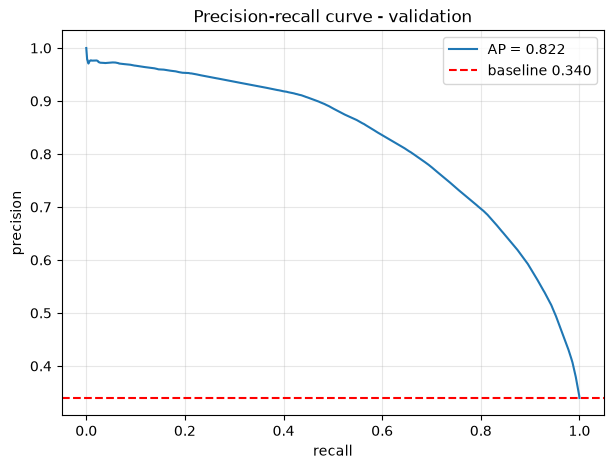

In [3]:
precision, recall, thresholds = clf.plot_pr_curve(x_val, y_val, name = 'validation')

## EVALUATION METRICS

TP    154507
FP     42852
FN     69613
TN    393079
dtype: int64

,precision,recall,f1-score,support
not severe,0.8495,0.9017,0.8748,435931.0000
severe,0.7829,0.6894,0.7332,224120.0000
accuracy,0.8296,0.8296,0.8296,0.8296
macro avg,0.8162,0.7955,0.8040,660051.0000
weighted avg,0.8269,0.8296,0.8267,660051.0000


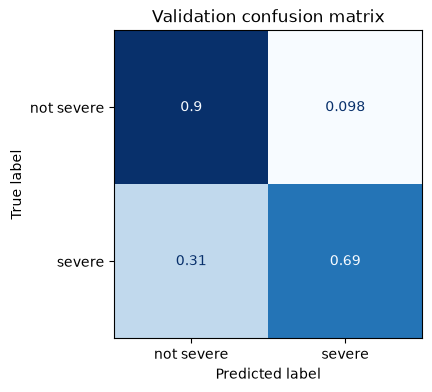

,rows,error_rate,missed_rate,false_alarm_rate
street_type,,,,
6.0,20643,0.2626,0.1616,0.1010
1.0,63317,0.2517,0.1286,0.1231
4.0,51556,0.2026,0.1522,0.0504
0.0,2205,0.1918,0.1107,0.0812
5.0,48945,0.1891,0.1560,0.0331
2.0,143481,0.1855,0.0217,0.1638
3.0,329583,0.1342,0.1188,0.0154


,rows,error_rate,missed_rate,false_alarm_rate
start_hour,,,,
2,2989,0.2405,0.1659,0.0746
3,3061,0.2378,0.1519,0.0859
0,3202,0.2358,0.1615,0.0743
1,2960,0.2314,0.1473,0.0841
23,4036,0.2161,0.1241,0.0919
5,21808,0.1919,0.1180,0.0739
21,12092,0.1891,0.1233,0.0657
22,9590,0.1870,0.1235,0.0635
4,17301,0.1850,0.1161,0.0689


street_type         0.6427
start_lng           0.0958
start_lat           0.0711
constraint_count    0.0661
state               0.0370
start_year          0.0325
start_hour          0.0207
start_day           0.0203
junction            0.0089
pressure(in)        0.0027
timezone(us)        0.0016
railway             0.0003
traffic_signal      0.0003
temperature(f)      0.0000
humidity(%)         0.0000
wind_direction      0.0000
visibility(mi)      0.0000
wind_speed(mph)     0.0000
stop                0.0000
no_exit             0.0000
dtype: float64

In [4]:
err = cea.ErrorAnalysis(y_val, y_val_preds, val_prob, x_val)

display(err.counts())
display(err.report_df())
err.plot_confusion_matrix()
display(err.errors_by('street_type'))
display(err.errors_by('start_hour'))
display(err.feature_importance(clf.model))

## TEST THE XGBOOST CLASSIFIER:

training model for binary classification
 number of trees across full model: 100
Train      acc 0.8645 | prec 0.8235 | rec 0.7639 | F1 0.7926 | PR-AUC 0.8734 | predicted severe 0.314 vs actual 0.339
Validation acc 0.8629 | prec 0.8209 | rec 0.7627 | F1 0.7907 | PR-AUC 0.8705 | predicted severe 0.315 vs actual 0.340


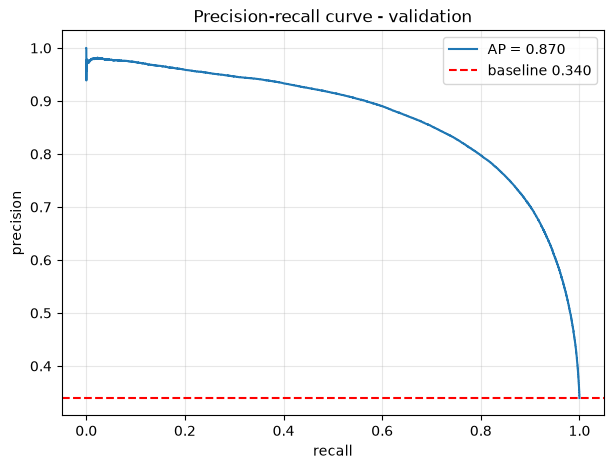

In [5]:
xgb = xgb.Xgboost(x_train, y_train, x_val, y_val, x_test, y_test)
# train on the xtrain and y_train values
xgb.train()

y_train_preds, train_prob, train_scores = xgb.evaluate_train()
y_val_preds, val_prob, val_scores = xgb.validate()

xgb_precision, xgb_recall, xgb_thresholds = xgb.plot_pr_curve(x_val, y_val)